In [1]:
import torch
import torchvision
from torchvision.datasets import CIFAR10

In [ ]:
# MNIST -> 1x28x28 -> 784
# CIFAR -> 3x32x32 -> 1024 * 3 = 3072

In [2]:
from torchvision import transforms as T

# tfs = T.Compose( [T.Resize((28, 28)), T.Grayscale(num_output_channels = 3), T.ToTensor()] ) # MNIST
tfs = T.Compose( [T.Resize((32, 32)), T.ToTensor()] )

ds = CIFAR10(root = "datasets", train = True, download = True, transform = tfs)
ts_ds = CIFAR10(root = "datasets", train = False, download = True, transform = tfs)
classes = ds.classes
print(classes)
n_cls = len(classes) # validation data is not used in this example, but it can be used for hyperparameter tuning and model selection.
n_cls

Files already downloaded and verified
Files already downloaded and verified
['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


10

In [3]:
from torch.utils.data import random_split, DataLoader

total_len = len(ds)
tr_len = int(total_len * 0.9) # int
vl_len = total_len - tr_len # int - int = int
tr_len, vl_len

(45000, 5000)

In [4]:
tr_ds, vl_ds = random_split(dataset = ds, lengths=[tr_len, vl_len]) # train va validation datasetlarini ajratamiz
print(len(tr_ds),len(vl_ds))  # train va validation datasetlarining uzunliklarini chiqaramiz

45000 5000


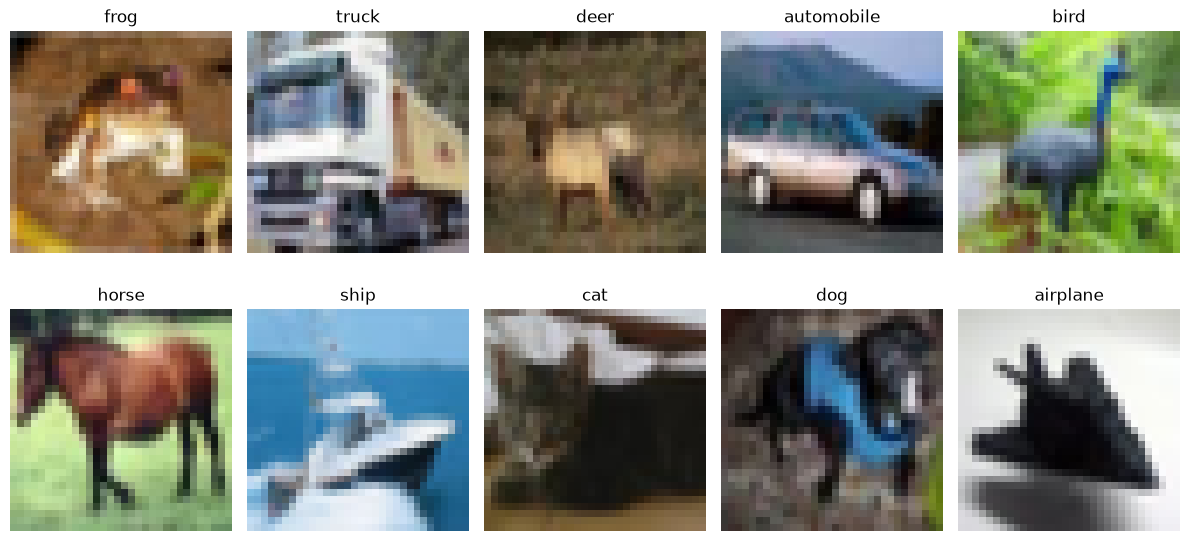

In [5]:
# CIFAR 10 datasetdagi imagelarni olib ko'ramiz.
import matplotlib.pyplot as plt

images_per_class = {} # har bir class uchun 1 ta image saqlash uchun dict
for img, label in ds:  # datasetdan rasmlar va ularning label(lar)ini olib olamiz
    class_name = classes[label] # class nomini olib olamiz
    if class_name not in images_per_class: # agar class nomi dict ichida bo'lmasa, uni qo'shamiz
        images_per_class[class_name] = img  # har bir class uchun 1 ta image saqlaymiz
    if len(images_per_class)==len(classes): break  # agar barcha classlar uchun 1 ta image saqlangan bo'lsa, loopni to'xtatamiz

#plt
plt.figure(figsize=(12,6))   # rasmlar uchun figure o'lchamini belgilaymiz
for idx, (class_name, img) in enumerate(images_per_class.items()): # har bir class nomi va unga tegishli image ni olamiz
    plt.subplot(2,5,idx+1)   # har bir image ni 2x5 gridda joylashtiramiz
    plt.imshow(img.permute(1,2,0)) # img tensorini (C,H,W) dan (H,W,C) ga o'zgartirib, rasmni ko'rsatamiz
    plt.title(class_name) # har bir image ostiga class nomini yozamiz
    plt.axis('off')   # har bir image uchun axislarni o'chiramiz
plt.tight_layout() # rasmlar orasidagi bo'shliqni moslashtiramiz
plt.show()  # rasmlarni ko'rsatamiz

In [6]:
bs = 128
tr_dl = DataLoader(dataset = tr_ds, batch_size = bs, shuffle = True, num_workers = 8)
vl_dl = DataLoader(dataset = vl_ds, batch_size = bs, shuffle = False, num_workers = 8)
ts_dl = DataLoader(dataset = ts_ds, batch_size = 1,  shuffle = False, num_workers = 8)

/Users/apple/Course/.venv311/lib/python3.11/site-packages/torch/utils/data/dataloader.py:558: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 4 (`cpuset` is not taken into account), which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(_create_warning_msg(


#AL Model with Linear Layers

In [ ]:
# CNN - convolution neural networks
# filter == kernel

In [14]:
import torch
from torch.nn import Conv2d, MaxPool2d
inp = torch.rand(1, 3, 32, 32) # 4D -> (bs, im_chs, im_h, im_w)
# 2 ni darajalari; 8 -> 16 -> 32
# stride -> filterning qadami
# conv = Conv2d(in_channels = 3, out_channels = 8, kernel_size = 3, padding = 1, stride = 1) # Linear in_features, out_features; out_channels == filter soniga == kernellar soniga
# formula: [(32 + 2 * 1 - 3) / 1] + 1 = 32
# conv = Conv2d(in_channels = 3, out_channels = 8, kernel_size = 3, padding = 0, stride = 1) # Linear in_features, out_features; out_channels == filter soniga == kernellar soniga
# formula: [(32 + 0 - 3) / 1] + 1 = 29 + 1 = 30

conv = Conv2d(in_channels = 3, out_channels = 8, kernel_size = 3, padding = 1, stride = 2) # Linear in_features, out_features; out_channels == filter soniga == kernellar soniga
# formula: [(32 + 2 - 3) / 2] + 1 = 15 + 1 = 16

mp = MaxPool2d(kernel_size = 2, stride = 2) # backpropda qatnashmaydi: trainable parametrlari yo'q
mp(inp).shape

#conv(inp).shape

torch.Size([1, 3, 16, 16])

In [15]:
from torch.nn import *

class CustomModel(Module):

  def __init__(self, in_fs, in_chs, out_fs, out_chs, ks, p, s,n_cls):
    super().__init__()

#  3 ta convolution layer va 2 ta linear layer
    self.conv_1 = Conv2d(in_channels = in_chs, out_channels = out_chs, kernel_size = ks, padding = p, stride = s)
    self.conv_2 = Conv2d(in_channels = out_chs, out_channels = out_chs * 2, kernel_size = ks, padding = p, stride = s)
    self.conv_3 = Conv2d(in_channels = out_chs * 2, out_channels = out_chs, kernel_size = ks, padding = p, stride = s)

    self.lin_layer = Linear(in_features = in_fs, out_features = out_fs)
    self.classifier = Linear(in_features = out_fs, out_features = n_cls)
    self.act = ReLU() # prelu, leaky relu, elu,...
    self.mp = MaxPool2d(kernel_size = 2, stride = 2)

  def forward(self, inp): 

    out = self.conv_1(inp)        # (bs, out_chs, im_h, im_w)
    out = self.mp(self.act(out))  # (bs, out_chs, im_h // 2, im_w // 2)
    out = self.conv_2(out)        # (bs, out_chs * 2, im_h // 2, im_w // 2)
    out = self.mp(self.act(out))  # (bs, out_chs * 2, im_h // 4, im_w // 4)

    bs = inp.shape[0]
    out = out.view(bs, -1)

    out = self.lin_layer(out)
    out = self.act(out)
    out = self.classifier(out)

    return out

inp = torch.rand(1,3,32,32)
out_fs = 256

m = CustomModel(in_chs = inp.shape[1], out_chs = 8, ks = 3, p = 1, s = 1, in_fs = 1024, out_fs = out_fs, n_cls = n_cls)
xom_bashorat = m(inp)
xom_bashorat.shape

torch.Size([1, 10])

In [ ]:
### Training Loop

In [23]:
# Modelimizda nechta parametr borligini kurishimiz muhim. Chunki modelimizda qancha parametr bo'lsa, shuncha ko'p xotira talab qilinadi va shuncha ko'p vaqt talab qilinadi. Shuning uchun modelimizda nechta parametr borligini hisoblaymiz.
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

count_parameters(model = m) # modelimiz buyerda m

267522

In [ ]:
class CustomModel1(Module): 

  def __init__(self, in_fs, in_chs, out_fs, out_chs, ks, p, s, n_cls): 
    super().__init__()  # bu

#  3 ta convolution layer va 3 ta linear layer
    self.conv_1 = Conv2d(in_channels = in_chs, out_channels = out_chs, kernel_size = ks, padding = p, stride = s) 
    self.conv_2 = Conv2d(in_channels = out_chs, out_channels = out_chs * 2, kernel_size = ks, padding = p, stride = s) 
    self.conv_3 = Conv2d(in_channels = out_chs * 2, out_channels = out_chs * 8, kernel_size = ks, padding = p, stride = s) 

    self.lin_layer1 = Linear(in_features = in_fs, out_features = out_fs) 
    self.lin_layer2 = Linear(in_features = out_fs, out_features = out_fs // 2)
    self.classifier = Linear(in_features = out_fs // 2, out_features = n_cls)
    self.act = ReLU() # prelu, leaky relu, elu,...
    self.mp = MaxPool2d(kernel_size = 2, stride = 2)

  def forward(self, inp): 

    out = self.conv_1(inp)        # (bs, out_chs, im_h, im_w)
    out = self.mp(self.act(out))  # (bs, out_chs, im_h // 2, im_w // 2)
    out = self.conv_2(out)        # (bs, out_chs * 2, im_h // 2, im_w // 2)
    out = self.mp(self.act(out))  # (bs, out_chs * 2, im_h // 4, im_w // 4)
    out = self.conv_3(out)        # (bs, out_chs * 8, im_h // 4, im_w // 4)
    out = self.mp(self.act(out))  # (bs, out_chs * 8, im_h // 8, im_w // 8)

    bs = inp.shape[0] # batch size ni olishimiz kerak, chunki out tensorining birinchi o'lchami batch size bo'ladi. Shuning uchun bs = inp.shape[0] deb olamiz.
    out = out.view(bs, -1)  # out tensorini 2D ga o'zgartiramiz, chunki Linear layer faqat 2D input qabul qiladi. Shuning uchun out tensorini (bs, -1) ga o'zgartiramiz. -1 bu yerda avtomatik ravishda out tensorining qolgan o'lchamlari hisoblanadi.

    out = self.lin_layer1(out) # bu yerda out tensorini lin_layer1 ga uzatamiz, chunki lin_layer1 out_features ni oladi va out_features ni chiqaradi. Shuning uchun out tensorini lin_layer1 ga uzatamiz.
    out = self.act(out) # bu yerda out tensorini act ga uzatamiz, chunki act ReLU activation function ni ishlatadi va out tensorini ReLU ga uzatamiz. Shuning uchun out tensorini act ga uzatamiz.
    out = self.lin_layer2(out)
    out = self.act(out)
    out = self.classifier(out)

    return out
inp = torch.rand(1,3,32,32)
out_fs = 256
n_cls = len(classes)
m1 = CustomModel1(in_chs = inp.shape[1], out_chs = 8, in_fs = 1024, out_fs = out_fs, ks = 3, p = 1, s = 1, n_cls = n_cls)
xom_bashorat1 = m1(inp)
xom_bashorat1.shape

torch.Size([1, 10])